# 14 – Jupiter (stage 11: planets)

**What:** A colour image of Jupiter from NIRCam data – starting with the inventory of programme 1373 (July/November 2022) and choosing a **pair of filters exposed at the same time**.

**Why only simultaneous pairs?** Jupiter rotates once in ≈ 9.9 h, i.e. ≈ 0.6° per minute. Between two exposures taken 27 min apart, cloud features near the centre of the disk move by several arcseconds – many tens of pixels – while the limb hardly moves. This cannot be corrected by a simple shift (as for the motion of Neptune and Uranus); it would need a projection onto a longitude/latitude grid ("derotation") – a later, separate stage. NIRCam's short- and long-wavelength channels expose **simultaneously**, so one such pair lines up without derotation. Two filters give a **two-colour image**.

**Further difference:** Jupiter is ≈ 40″ across – larger than one short-wavelength detector. Products may be subarrays (`sub640`, `sub160`: only part of the detector read out) or mosaics. Step 1 shows which observations cover the whole disk.

## Result

Jupiter from a single pair of filters exposed at the same time (F212N + F335M, programme 1373, o008, 27 July 2022), close-up 50″ × 50″ at 0.031″/px.

- **A_bicolour** (chromatic: F212N blue, synthetic mean channel green, F335M red) – reference.
- **B_warm_bands** (chosen freely: F212N gold-orange, F335M cyan-blue) – aesthetic, loosely based on Jupiter's look in visible light.

Both in `output/jupiter_*`, all values in `params/jupiter.json`. Stretch asinh a = 0.2 (compared with 0.1: much more band detail).

## 1. Inventory: observations, products, timing

For every i2d product of programme 1373: observation, filter, subarray (from the file name), size, start time and exposure. Products with the **same start time** in the short- and long-wavelength channel are a simultaneous pair. No download.

In [1]:
from pathlib import Path
import re
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.time import Time
from astropy.table import Table
from astroquery.mast import Observations
from astropipe import bands, mast, registration

# ---- target-specific parameters ------------------------------------------------
TARGET = "Jupiter"
PROGRAM = 1373
PAIR = "jw01373-o008_t006_"
DOWNLOAD = True
# ----------------------------------------------------------------------------------

ROOT = Path("..")
RAW = ROOT / f"data/{TARGET.lower()}_{PROGRAM}_nircam"

obs = Observations.query_criteria(obs_collection="JWST", proposal_id=str(PROGRAM), instrument_name="NIRCAM/IMAGE",
                                  calib_level=3, target_name=TARGET.upper())
rows = []
for o in obs:
    rows.append(dict(obs=o["obs_id"].split("_nircam")[0], filters=o["filters"],
                     sub=(re.search(r"(sub\d+)", o["obs_id"]) or [None, "full"])[1],
                     start=Time(o["t_min"], format="mjd").iso[:16], end=Time(o["t_max"], format="mjd").iso[11:16],
                     exp_s=round(float(o["t_exptime"]), 1), obs_id=o["obs_id"]))
inv = Table(rows)
inv.sort(["start", "filters"])
inv["obs", "start", "end", "filters", "sub", "exp_s"].pprint(max_lines=-1, max_width=-1)

       obs             start        end    filters     sub   exp_s
----------------- ---------------- ----- ------------ ------ -----
jw01373-o006_t006 2022-07-27 10:24 10:36 F150W2;F164N sub640 150.7
jw01373-o006_t006 2022-07-27 10:24 10:36        F360M sub640 150.7
jw01373-o008_t006 2022-07-27 10:51 11:00        F212N   full 161.1
jw01373-o008_t006 2022-07-27 10:51 11:00        F335M   full 161.1
jw01373-o007_t006 2022-07-27 20:23 20:35 F150W2;F164N sub640 150.7
jw01373-o007_t006 2022-07-27 20:23 20:35  F444W;F405N sub640 150.7
jw01373-o009_t006 2022-07-27 20:54 21:02        F212N   full 161.1
jw01373-o009_t006 2022-07-27 20:54 21:02        F335M   full 161.1
jw01373-o010_t006 2022-07-28 20:35 20:44        F212N   full 128.8
jw01373-o010_t006 2022-07-28 20:35 20:44        F250M   full 128.8
jw01373-o010_t006 2022-07-28 20:49 21:16       F150W2   full 966.3
jw01373-o010_t006 2022-07-28 20:49 21:16       F322W2   full 966.3
jw01373-o012_t006 2022-07-29 02:14 02:23        F212N   full 1

In [2]:
# sizes of the i2d files (products), grouped per observation
prods = Observations.get_product_list(obs)
i2d = Observations.filter_products(prods, productType="SCIENCE", productSubGroupDescription="I2D", calib_level=[3])
for name, size in sorted(zip(i2d["productFilename"], i2d["size"])):
    print(f"{name:60s} {size / 1e6:8.1f} MB")
print(f"{len(i2d)} files, {mast.total_size_gb(i2d):.2f} GB in total")

jw01373-o006_t006_nircam_clear-f360m-sub640_i2d.fits             15.5 MB
jw01373-o006_t006_nircam_f150w2-f164n-sub640_i2d.fits            75.2 MB
jw01373-o007_t006_nircam_f150w2-f164n-sub640_i2d.fits            75.2 MB
jw01373-o007_t006_nircam_f405n-f444w-sub640_i2d.fits             15.5 MB
jw01373-o008_t006_nircam_clear-f212n_i2d.fits                   525.1 MB
jw01373-o008_t006_nircam_clear-f335m_i2d.fits                   120.5 MB
jw01373-o009_t006_nircam_clear-f212n_i2d.fits                   526.5 MB
jw01373-o009_t006_nircam_clear-f335m_i2d.fits                   120.8 MB
jw01373-o010_t006_nircam_clear-f150w2_i2d.fits                  526.4 MB
jw01373-o010_t006_nircam_clear-f212n_i2d.fits                   526.5 MB
jw01373-o010_t006_nircam_clear-f250m_i2d.fits                   120.8 MB
jw01373-o010_t006_nircam_clear-f322w2_i2d.fits                  120.8 MB
jw01373-o012_t006_nircam_clear-f150w2_i2d.fits                  526.4 MB
jw01373-o012_t006_nircam_clear-f212n_i2d.fits      

**Checkpoint:** choose one simultaneous pair (same `start`, one short- and one long-wavelength filter), preferably **without** `sub` (whole field) and with an exposure that does not saturate the disk. Set `PAIR` to its observation prefix in the parameter cell, then `DOWNLOAD = True` and run the next cell.

In [3]:
sel = i2d[[PAIR is not None and n.startswith(PAIR) for n in i2d["productFilename"]]]
print(len(sel), f"files, {mast.total_size_gb(sel):.2f} GB")
if DOWNLOAD and len(sel):
    mast.download(sel, RAW, max_gb=3.0)
FILES = {bands.band_from_header(fits.getheader(f, 0)): f for f in sorted(RAW.glob(f"{PAIR}*_i2d.fits"))} if PAIR else {}
FILES

2 files, 0.65 GB
2 of 2 files already present, 0 to download (0.00 GB)


{'F212N': PosixPath('../data/jupiter_1373_nircam/jw01373-o008_t006_nircam_clear-f212n_i2d.fits'),
 'F335M': PosixPath('../data/jupiter_1373_nircam/jw01373-o008_t006_nircam_clear-f335m_i2d.fits')}

## 2. First look

Each downloaded filter in its own pixel grid: whole image and the header timing. Things to look at: is the whole disk inside the image? Saturated areas (NaN)? Moons, rings?

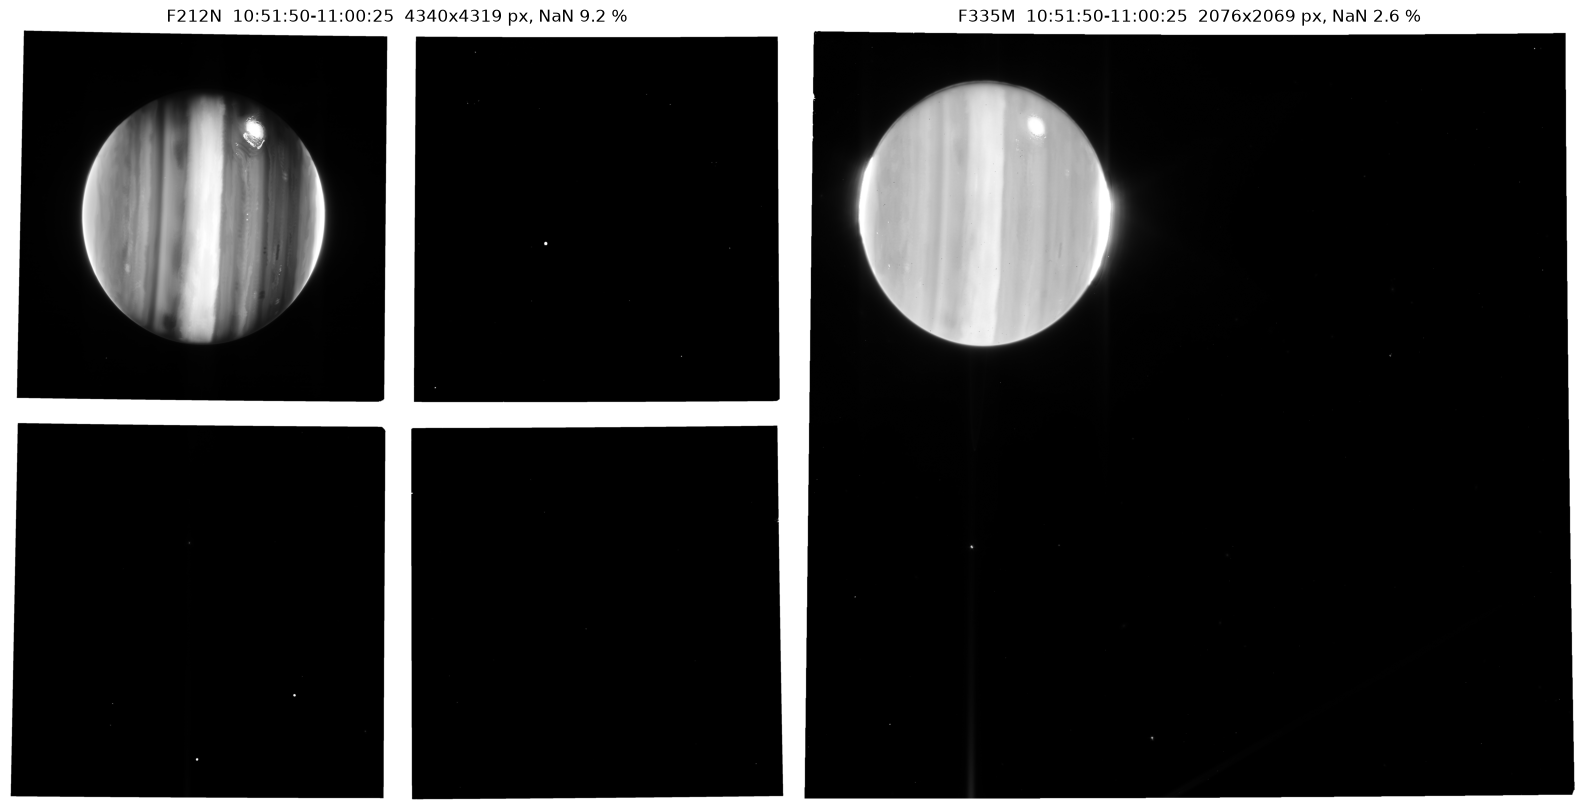

In [4]:
from astropy.visualization import AsinhStretch, PercentileInterval, ImageNormalize
fig, axes = plt.subplots(1, max(len(FILES), 1), figsize=(8 * max(len(FILES), 1), 8), squeeze=False)
for ax, (b, f) in zip(axes[0], FILES.items()):
    h0 = fits.getheader(f, 0)
    d = fits.getdata(f, extname="SCI")
    norm = ImageNormalize(d, interval=PercentileInterval(99.8), stretch=AsinhStretch(0.05))
    ax.imshow(d, origin="lower", cmap="gray", norm=norm)
    ax.set_title(f"{b}  {h0['DATE-BEG'][11:19]}-{h0['DATE-END'][11:19]}  {d.shape[1]}x{d.shape[0]} px, "
                 f"NaN {np.isnan(d).mean() * 100:.1f} %")
    ax.axis("off")
plt.tight_layout()

## 3. Stripes

Automatic check as in the explorer, and the comparison on F212N around the disk: raw, row destriping on empty sky (no high-pass), plus 2-D background. For Uranus the 2-D background removed part of the planet's halo – Jupiter is even brighter, so it is **off by default** here; the comparison shows whether that is right.

In [5]:
from astropy.wcs import WCS
from astropipe import clean, color, export, stretch
from astropipe.run import assess_field
import json

WORK = ROOT / f"data/{TARGET.lower()}_nb"
WORK.mkdir(parents=True, exist_ok=True)


def show(ax, img, title="", pct=99.5, a=0.02):
    norm = ImageNormalize(img, interval=PercentileInterval(pct), stretch=AsinhStretch(a))
    ax.imshow(img, origin="lower", cmap="gray", norm=norm)
    ax.set_title(title)
    ax.axis("off")


def cut(img, cy, cx, half):
    cy, cx = int(round(cy)), int(round(cx))
    return img[max(cy - half, 0):cy + half, max(cx - half, 0):cx + half]


raw = {b: fits.getdata(p, extname="SCI").astype(np.float32) for b, p in FILES.items()}
pix = {b: float(registration.pixel_scale_arcsec(WCS(fits.getheader(p, extname="SCI")))[0]) for b, p in FILES.items()}
cen_raw = {b: registration.disk_centroid(im) for b, im in raw.items()}
field = assess_field(FILES)
print("empty field:", field["empty_field"], "  pixel scales:", pix)

[12:00:06] field type: extended object fills the field
[12:00:06] F212N: structure 2.6 sigma, sky 0.77, stripes rows 0.21 / columns 0.09 -> local (rows), 2-D bg 0
[12:00:06] F335M: structure 4.8 sigma, sky 0.66, stripes rows 0.12 / columns 0.12 -> none (columns), 2-D bg 0
empty field: False   pixel scales: {'F212N': 0.03074658403493717, 'F335M': 0.06300677787600743}


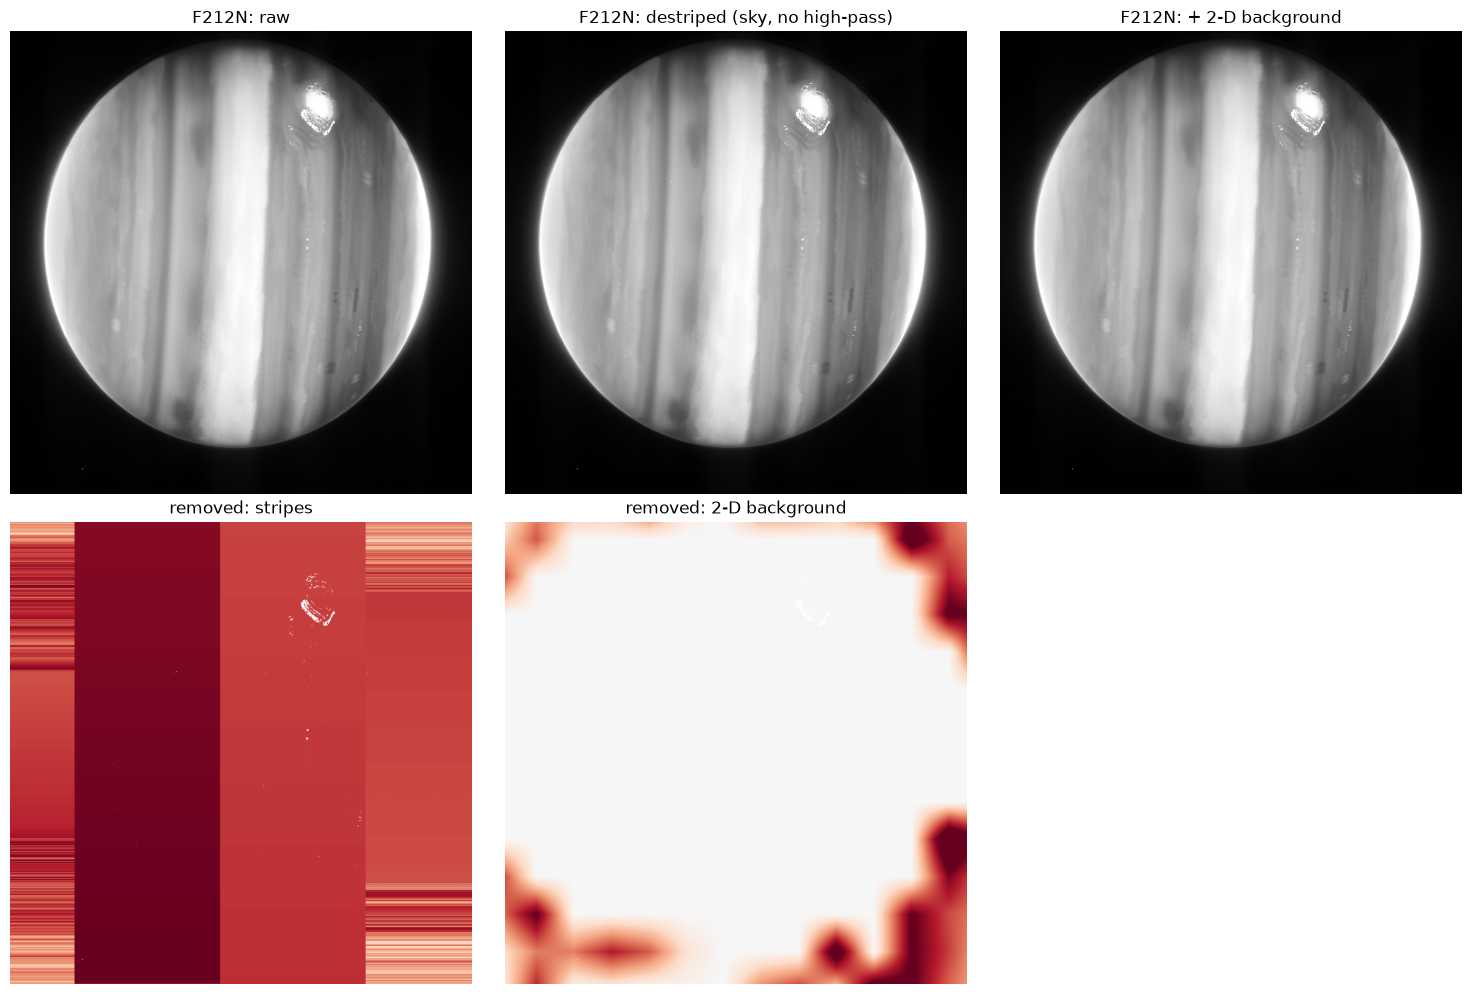

In [6]:
B = "F212N"
FIELD_ARCSEC = 50.0                      # Jupiter ≈ 44" in July 2022 (to be checked in the image)
img = raw[B]
sky, _, _ = clean.destripe(img, "rows", smooth=0, segment=512)
sky_bg, _ = clean.subtract_background_2d(sky, cell=128)
cy, cx = cen_raw[B]
h = int(FIELD_ARCSEC / 2 / pix[B])
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, im, t in zip(axes[0], [img, sky, sky_bg], ["raw", "destriped (sky, no high-pass)", "+ 2-D background"]):
    show(ax, cut(im, cy, cx, h), f"{B}: {t}", pct=99.0, a=0.01)
for ax, im, t in zip(axes[1], [img - sky, sky - sky_bg], ["removed: stripes", "removed: 2-D background"]):
    c = cut(im, cy, cx, h)
    s = np.nanpercentile(np.abs(c), 99)
    ax.imshow(c, origin="lower", cmap="RdBu_r", vmin=-s, vmax=s)
    ax.set_title(t)
    ax.axis("off")
axes[1, 2].axis("off")
plt.tight_layout()

**Checkpoint:** keep the destriping? Use the 2-D background (only if it does not remove the planet's halo unevenly)?

In [7]:
USE_DESTRIPE, USE_BG2D = True, False

cleaned = {}
for b, f in FILES.items():
    out = raw[b]
    if USE_DESTRIPE:
        out, _, _ = clean.destripe(out, "rows", smooth=0, segment=512)
    if USE_BG2D:
        out, _ = clean.subtract_background_2d(out, cell=128)
    dest = WORK / "cleaned" / f.name.replace("_i2d", "_clean_i2d")
    clean.write_cleaned_i2d(f, dest, out, f"14_jupiter: destripe={USE_DESTRIPE}, bg2d={USE_BG2D}")
    cleaned[b] = dest
    print(b, "->", dest.name)

F212N -> jw01373-o008_t006_nircam_clear-f212n_clean_i2d.fits
F335M -> jw01373-o008_t006_nircam_clear-f335m_clean_i2d.fits


## 4. Close-up grid

Both filters were exposed at the same time, so the moving-target shift is zero – it is still applied (same code as for Neptune/Uranus, it simply shifts by 0). Grid: `FIELD_ARCSEC`, north up, centred on Jupiter's mean position, at the short-wavelength pixel scale (≈ 0.031″); F335M is upsampled ×2 (no new detail).

**Check:** disk centre in both filters (threshold from the F212N disk). F335M has a bright limb and a more uniform disk – if the centres differ by more than ~1 px, look at the overlay before trusting the number (simultaneous exposures cannot be shifted against each other).

In [8]:
offs = registration.moving_target_offsets(cleaned)
shifted = {}
for b, f in cleaned.items():
    dra, ddec = offs[b]
    shifted[b] = registration.write_shifted_i2d(f, WORK / "mt" / f.name.replace(".fits", "_mt.fits"), dra, ddec)
    print(f"{b}: WCS shifted by ({dra * 3600:+.3f}\", {ddec * 3600:+.3f}\")")

h1 = fits.getheader(next(iter(FILES.values())), extname="SCI")
ra0, dec0 = h1["MT_AVRA"], h1["MT_AVDEC"]
RES = min(pix.values())
n = int(round(FIELD_ARCSEC / RES))
wcs_out = WCS(naxis=2)
wcs_out.wcs.ctype = ["RA---TAN", "DEC--TAN"]
wcs_out.wcs.crval = [ra0, dec0]
wcs_out.wcs.crpix = [(n + 1) / 2, (n + 1) / 2]
wcs_out.wcs.cdelt = [-RES / 3600, RES / 3600]
shape_out = (n, n)
reproj = registration.reproject_all(shifted, wcs_out, shape_out, WORK / "reproj_zoom", f"{TARGET.lower()}_zoom")
imgs = {b: fits.getdata(p).astype(np.float32) for b, p in reproj.items()}
print("grid", shape_out, f"at {RES:.4f}\"/px")

F212N: WCS shifted by (+0.000", +0.000")
F335M: WCS shifted by (-0.000", +0.000")
F212N   outdated (made from jw01373-o008_t006_nircam_clear-f212n_clean_i2d_mt.fits) -> reprojecting
F212N      3.4 s -> jupiter_zoom_f212n_reproj.fits
F335M   outdated (made from jw01373-o008_t006_nircam_clear-f335m_clean_i2d_mt.fits) -> reprojecting
F335M      3.3 s -> jupiter_zoom_f335m_reproj.fits
grid (1626, 1626) at 0.0307"/px


grid centre (812.5, 812.5);  disk ≈ 12.2" across
F212N: disk centre (828.7, 749.7), offset vs F212N 0.00 px
F335M: disk centre (863.7, 760.1), offset vs F212N 36.47 px


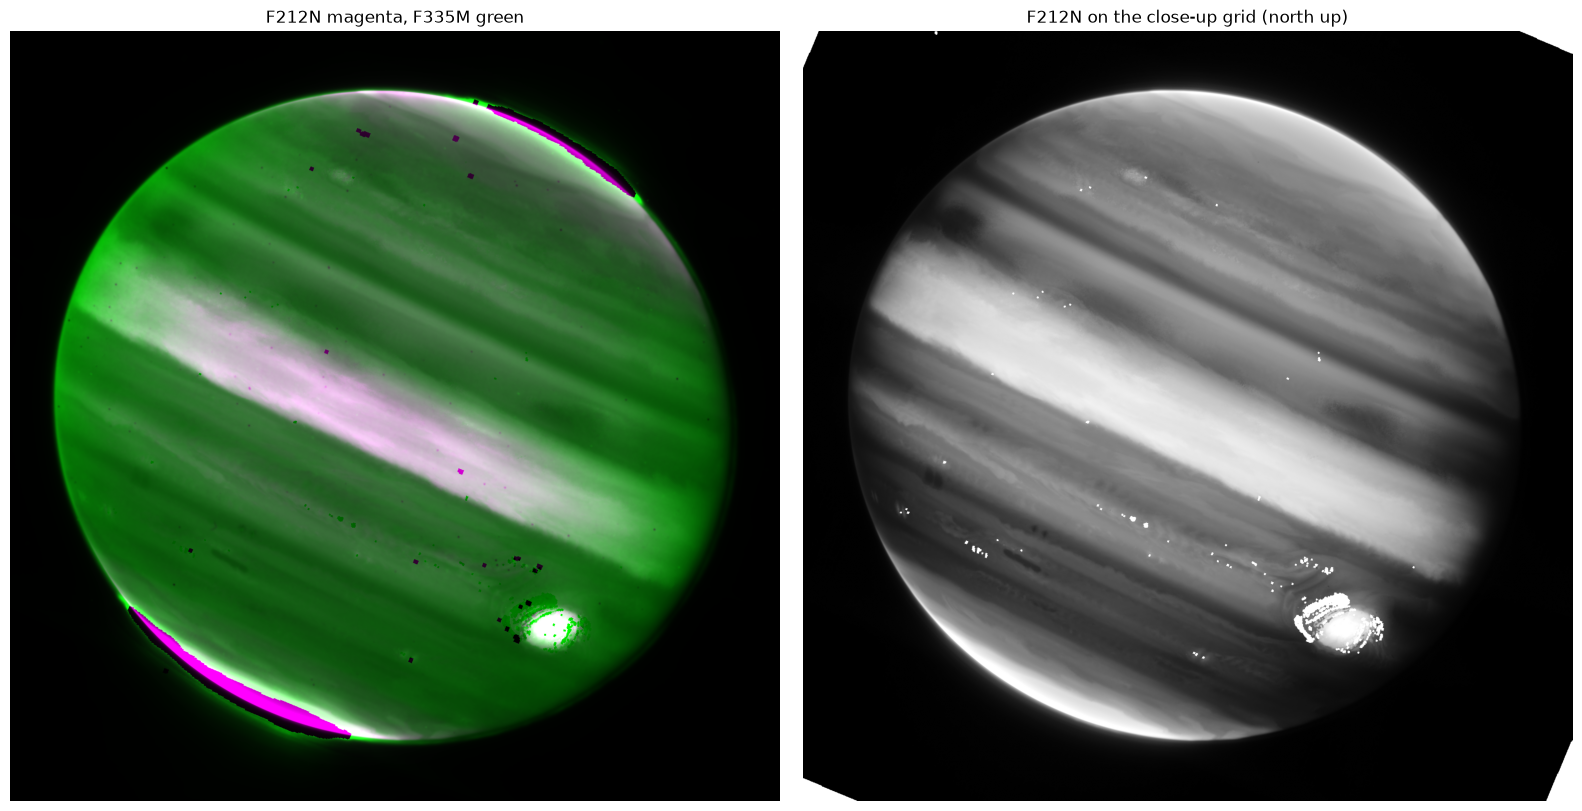

In [9]:
REF = "F212N"
ref_disk = registration.disk_mask(imgs[REF])
cen = {b: registration.disk_centroid(im, ref_mask=ref_disk) for b, im in imgs.items()}
y0, x0 = cen[REF]
r_disk = np.sqrt(ref_disk.sum() / np.pi)
print(f"grid centre ({(n - 1) / 2:.1f}, {(n - 1) / 2:.1f});  disk ≈ {2 * r_disk * RES:.1f}\" across")
for b, c in cen.items():
    print(f"{b}: disk centre ({c[0]:.1f}, {c[1]:.1f}), offset vs {REF} {np.hypot(c[0] - y0, c[1] - x0):.2f} px")


def norm01(c, pct=99.5):
    c = np.nan_to_num(c)
    lo, hi = np.percentile(c, [1, pct])
    return np.clip((c - lo) / (hi - lo), 0, 1)


m, g = norm01(imgs["F212N"]), norm01(imgs["F335M"])
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(np.dstack([m, g, m]), origin="lower")
axes[0].set_title("F212N magenta, F335M green")
axes[0].axis("off")
show(axes[1], imgs["F212N"], "F212N on the close-up grid (north up)", pct=99.5, a=0.05)
plt.tight_layout()

## 5. Bad pixels and saturated features

As for Uranus: bad pixels → median of the surroundings, saturated features → maximum of the surroundings; `UNIFY_SATURATED`: white in both filters where saturated in either.

In [10]:
from scipy import ndimage as ndi
UNIFY_SATURATED = True


def planet_mask(img, frac=0.05):
    """Whole planet: everything clearly brighter than the sky (largest region, holes filled)."""
    lab, nlab = ndi.label(np.nan_to_num(img) > frac * np.nanpercentile(img, 99))
    sizes = ndi.sum(np.ones_like(lab), lab, np.arange(1, nlab + 1))
    return ndi.binary_fill_holes(lab == int(np.argmax(sizes)) + 1)


planet = planet_mask(imgs["F212N"])
planet_fill = ndi.binary_dilation(planet, iterations=15)   # limb haze reaches slightly beyond the cloud disk
print(f"planet ≈ {2 * np.sqrt(planet.sum() / np.pi) * RES:.1f} arcsec across")
filled, sat_union = {}, np.zeros(planet.shape, bool)
for b, im in imgs.items():
    lab, holes = stretch.classify_holes(im)
    for hh in holes:
        if hh["saturated"]:
            sat_union |= lab == hh["label"]
    filled[b], n_sat, n_bad = stretch.fill_holes(im, sat_fill="local")
    big = np.isnan(filled[b]) & planet_fill      # large saturated areas on the planet (bright limb haze, GRS in F335M)
    filled[b][big] = np.nanmax(filled[b])
    sat_union |= big
    print(f"{b}: saturated {n_sat} px, bad/flagged {n_bad} px, large saturated areas on the planet {int(big.sum())} px, "
          f"NaN left {int(np.isnan(filled[b]).sum())}")
print("saturated in at least one filter:", int(sat_union.sum()), "px")

planet ≈ 40.3 arcsec across
F212N: saturated 0 px, bad/flagged 5008 px, large saturated areas on the planet 2888 px, NaN left 10646
F335M: saturated 0 px, bad/flagged 2213 px, large saturated areas on the planet 28880 px, NaN left 29138
saturated in at least one filter: 31768 px


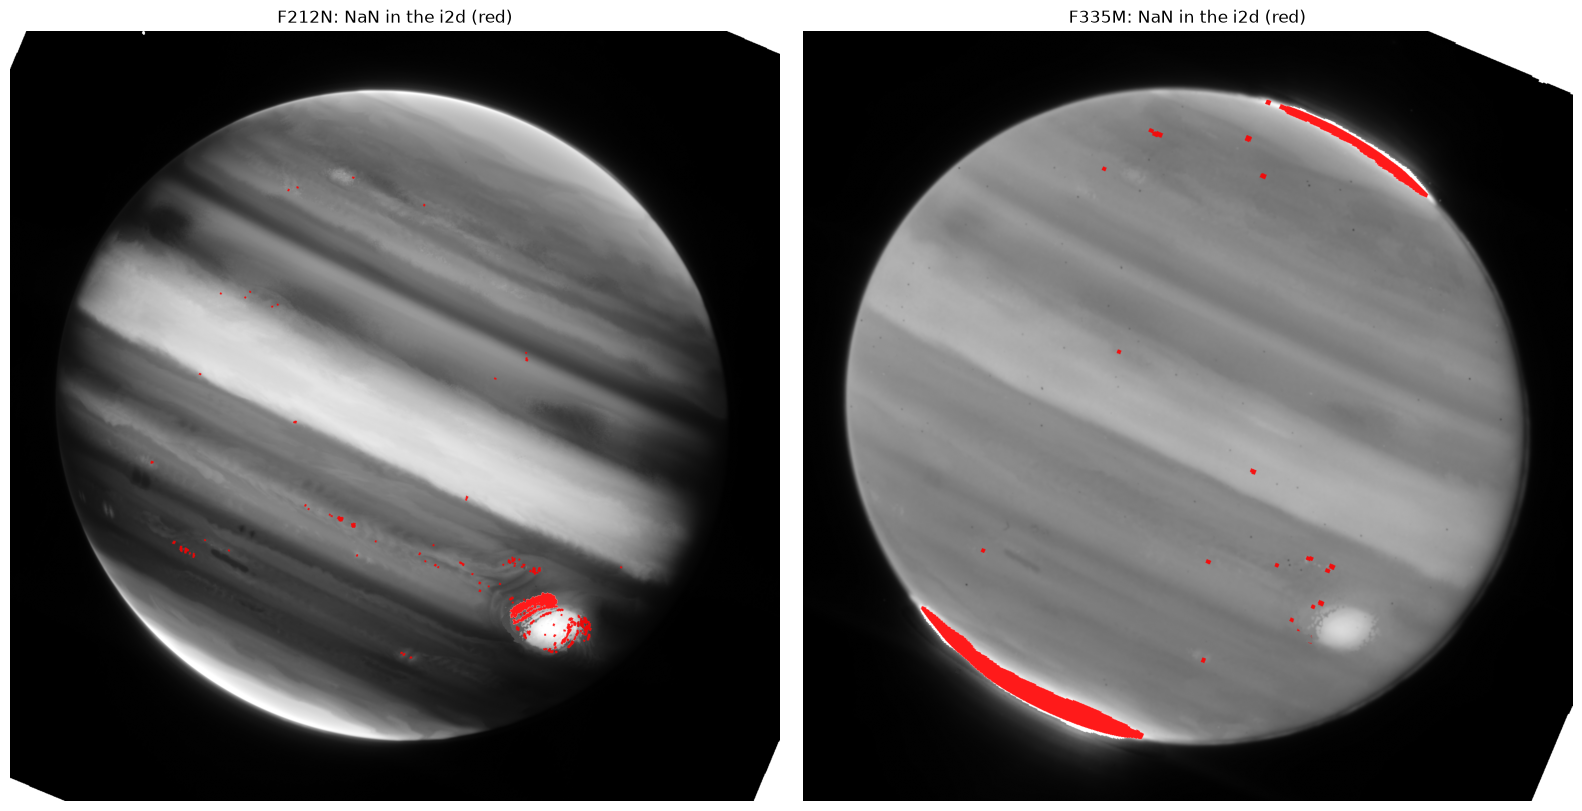

In [11]:
# Where did the pipeline leave no value (NaN) on the planet? (diagnostic, not part of the colour image)
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, b in zip(axes, imgs):
    show(ax, filled[b], f"{b}: NaN in the i2d (red)", pct=99.5, a=0.05)
    holes = np.isnan(imgs[b]) & planet
    ax.imshow(np.ma.masked_where(~holes, holes), origin="lower", cmap="autumn", alpha=0.9)
plt.tight_layout()

F335M: 180 dark spots filled with the local median (4017 px)


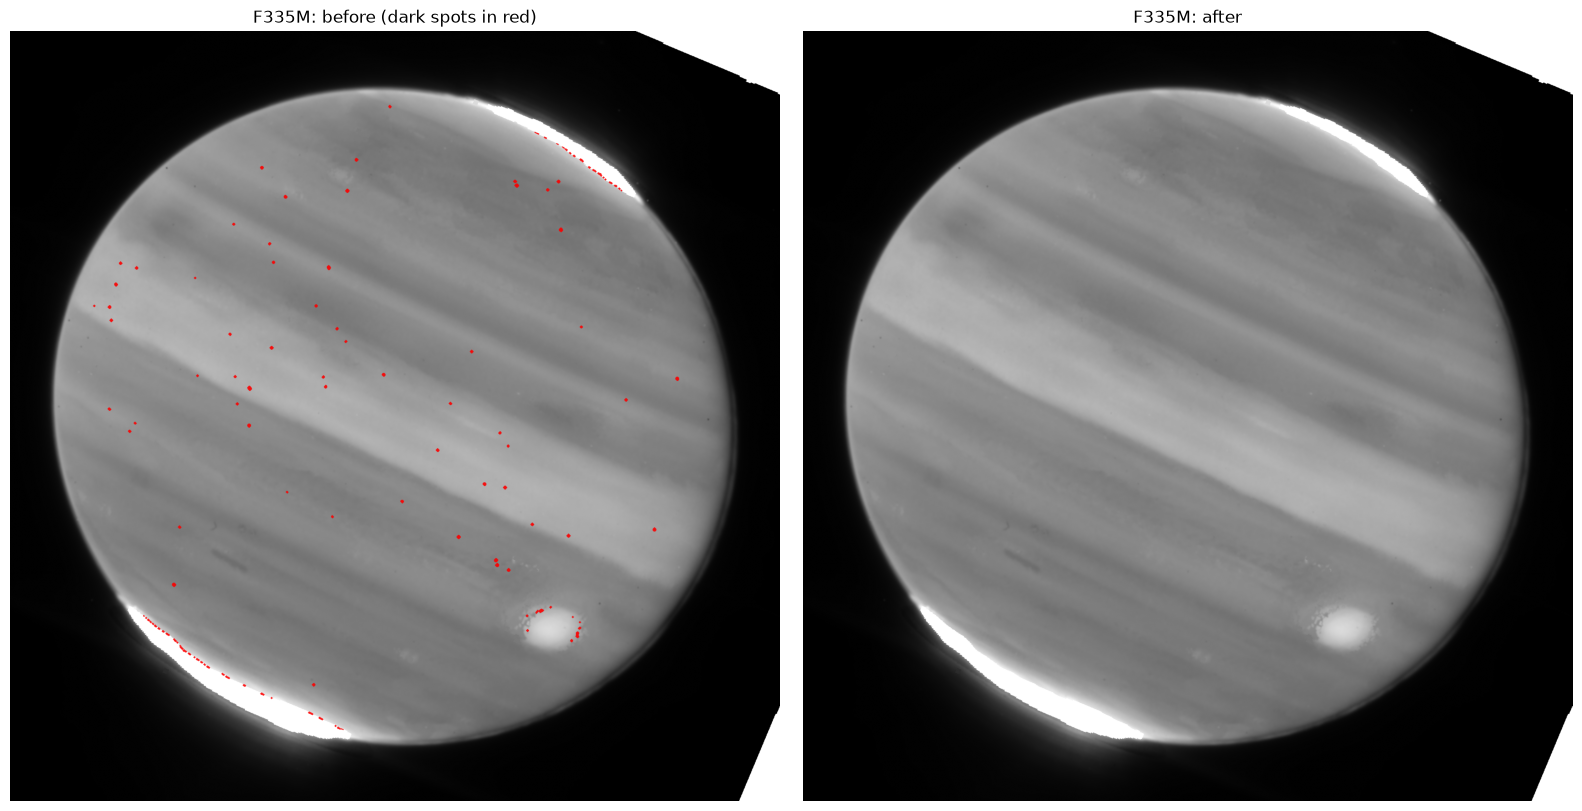

In [12]:
# 5b. Isolated dark spots that the pipeline did NOT flag (no NaN) – found in F335M only
DARK_SPOT_BANDS = ["F335M"]
DARK_THR, DARK_MAX_PX, DARK_MED = 0.85, 40, 15
inner = ndi.binary_erosion(planet, iterations=20)        # stay away from the limb
dark_spots, n_dark = {}, {}
unfixed = {b: im.copy() for b, im in filled.items()}     # state before the dark-spot fix (for the comparison in 7b)
for b in DARK_SPOT_BANDS:
    med = ndi.median_filter(filled[b], DARK_MED)
    low = (filled[b] / med < DARK_THR) & inner
    lab, nlab = ndi.label(low)
    sizes = ndi.sum(low, lab, np.arange(1, nlab + 1))
    keep = np.isin(lab, 1 + np.nonzero(sizes <= DARK_MAX_PX)[0])
    dark_spots[b] = ndi.binary_dilation(keep, iterations=2) & inner
    n_dark[b] = int((sizes <= DARK_MAX_PX).sum())
    before = filled[b].copy()
    filled[b] = np.where(dark_spots[b], med, filled[b])
    print(f"{b}: {n_dark[b]} dark spots filled with the local median ({int(dark_spots[b].sum())} px)")

    fig, axes = plt.subplots(1, 2, figsize=(16, 8))
    show(axes[0], before, f"{b}: before (dark spots in red)", pct=99.5, a=0.05)
    axes[0].imshow(np.ma.masked_where(~dark_spots[b], dark_spots[b]), origin="lower", cmap="autumn", alpha=0.9)
    show(axes[1], filled[b], f"{b}: after", pct=99.5, a=0.05)
    plt.tight_layout()

## 6. Background and stretch

Background from small boxes in the corners (outside the disk), white point from the disk (99.5 % of its pixels) per filter, comparison of asinh strengths. Jupiter's disk is large and bright with a lot of internal contrast (bands, Great Red Spot) – probably a weaker stretch than for Neptune/Uranus fits best.

4 sky boxes: [(50, 1500), (1425, 1575), (1575, 50), (100, 0)]   disk: 1322189 px
F212N: bkg -5.9441  noise 1.8008  white from disk (99.5 %) 20612.264
F335M: bkg 1.4517  noise 0.1469  white from disk (99.5 %) 1743.478


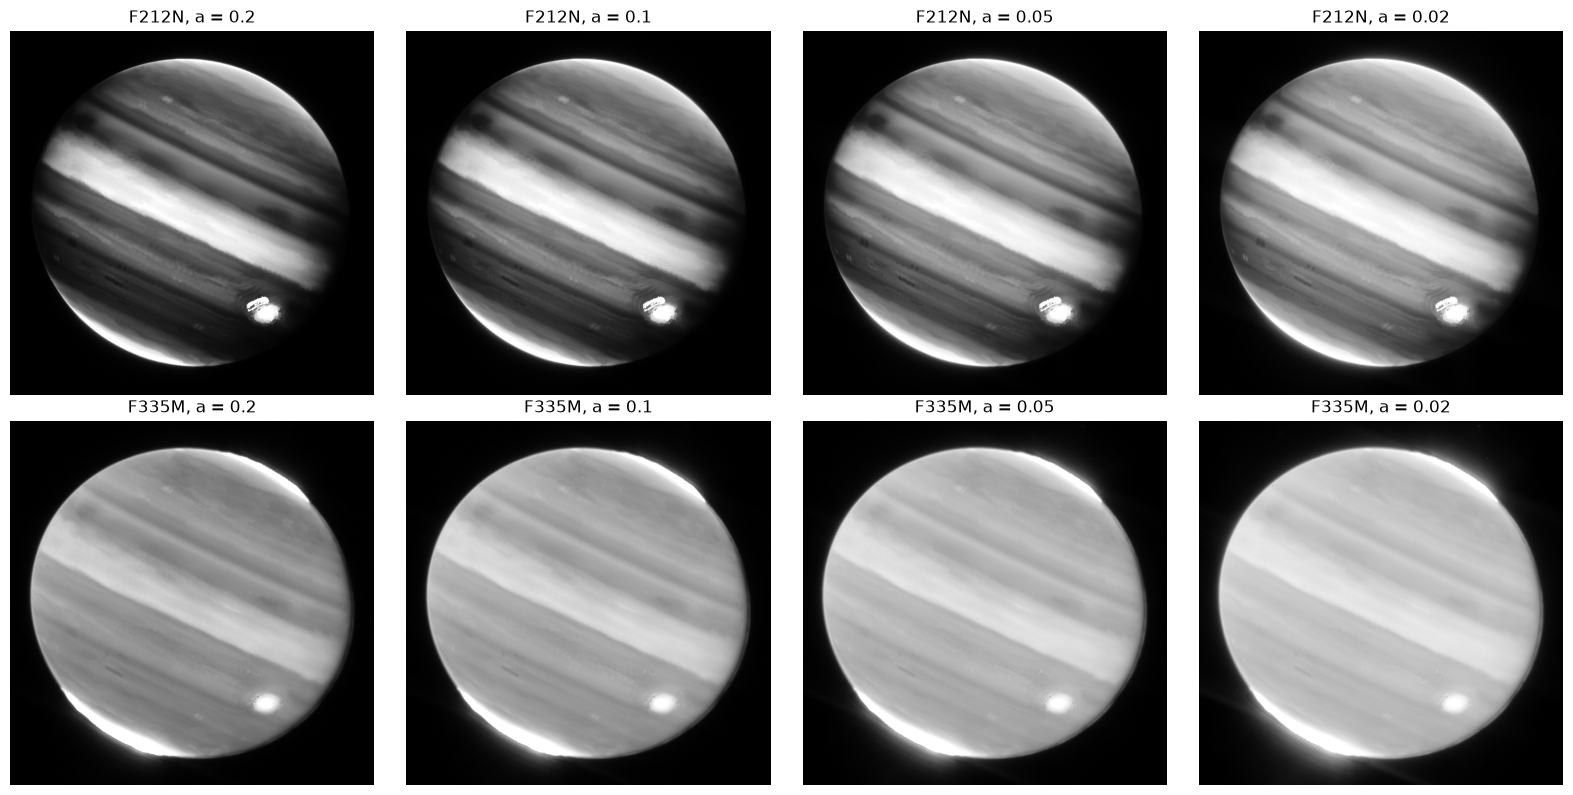

In [13]:
valid = stretch.common_valid(filled)
boxes, scores = stretch.find_sky_boxes(filled, valid, box=50, edge_margin=10, n_boxes=4, min_sep=300)
stats = stretch.sky_stats(filled, boxes, 50)
disk = planet & ~sat_union      # white point from measured pixels only (not from the filled saturated areas)
print(len(boxes), "sky boxes:", boxes, "  disk:", int(disk.sum()), "px")
for b in filled:
    x = filled[b] - stats[b]["bkg"]
    print(f"{b}: bkg {stats[b]['bkg']:.4f}  noise {stats[b]['noise']:.4f}  white from disk (99.5 %) "
          f"{np.percentile(x[disk & valid], 99.5):.3f}")

A_VALUES = [0.2, 0.1, 0.05, 0.02]
fig, axes = plt.subplots(2, len(A_VALUES), figsize=(4 * len(A_VALUES), 8))
for row, b in enumerate(filled):
    white = float(np.percentile((filled[b] - stats[b]["bkg"])[disk & valid], 99.5))
    y, _, _ = stretch.normalize(filled[b], valid, stats[b]["bkg"], stats[b]["noise"], 0.5, 99.9, white)
    for ax, a in zip(axes[row], A_VALUES):
        ax.imshow(stretch.asinh_stretch(y, a), origin="lower", cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"{b}, a = {a}")
        ax.axis("off")
plt.tight_layout()

**Checkpoint:** choose `A_VALUE` (can be different per filter via `A_BAND`).

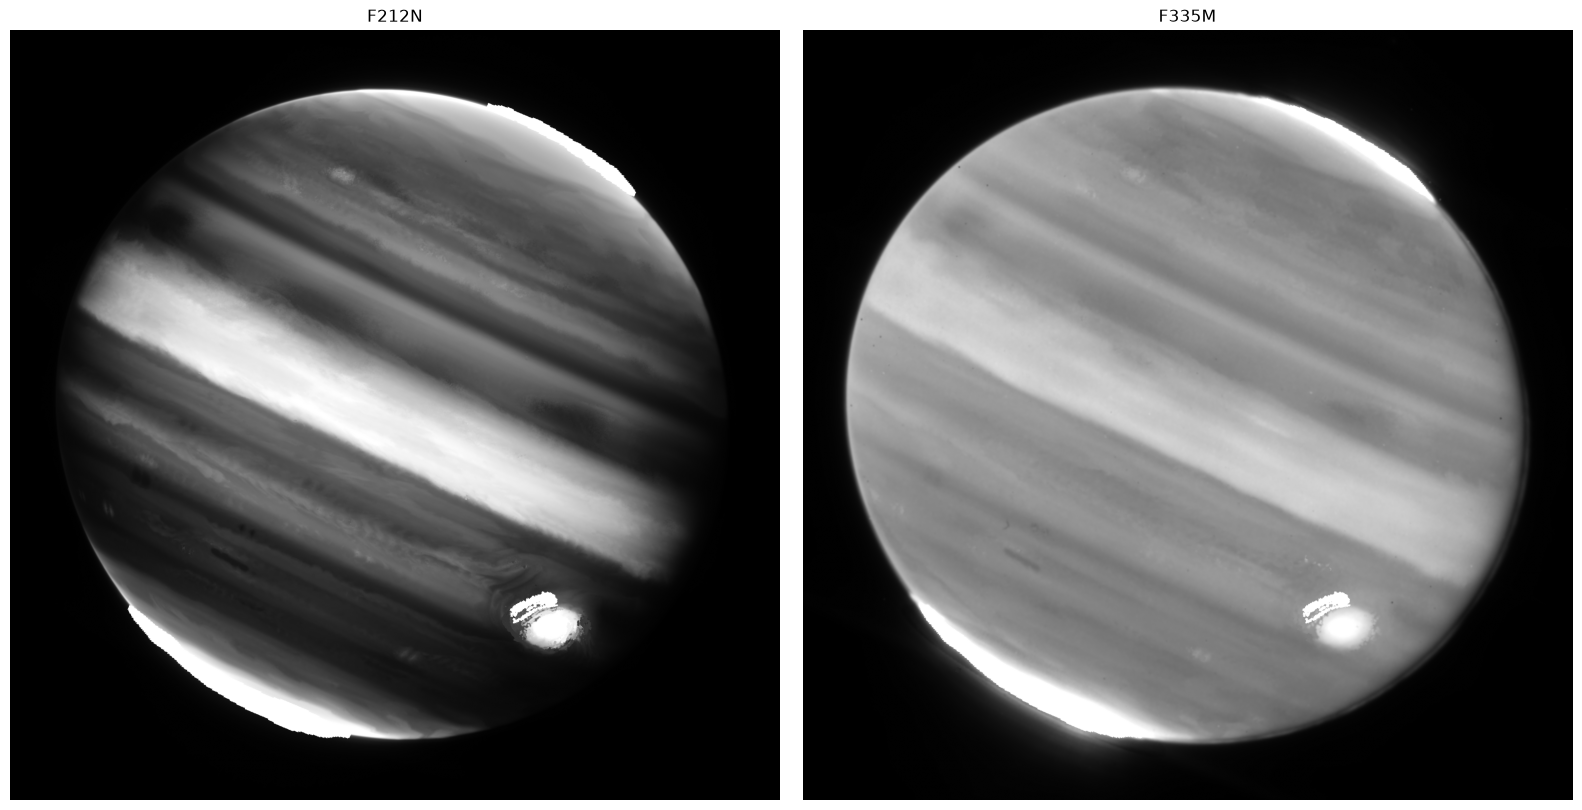

In [14]:
A_VALUE, BLACK_K, WHITE_PCT_DISK = 0.2, 0.5, 99.5
A_BAND = {}                     # e.g. {"F335M": 0.02}

params = {}
for b in filled:
    x = filled[b] - stats[b]["bkg"]
    params[b] = dict(black_k=BLACK_K, white_pct=99.9, a=A_BAND.get(b, A_VALUE),
                     white_value=float(np.percentile(x[disk & valid], WHITE_PCT_DISK)))
stretched, levels = stretch.stretch_all(filled, valid, stats, params)
if UNIFY_SATURATED:
    for b in stretched:
        stretched[b][sat_union] = 1.0
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, b in zip(axes, stretched):
    ax.imshow(stretched[b], origin="lower", cmap="gray", vmin=0, vmax=1)
    ax.set_title(b)
    ax.axis("off")
plt.tight_layout()

## 7. Colour from two filters

With only two filters, a third channel has to be made up. Common practice in amateur two-filter processing: a **synthetic channel = mean of the two** (here `SYN`), placed between them on the colour wheel.

- **A_bicolour** (chromatic order): F212N blue (240°), SYN green (120°), F335M red (0°).
- **B_warm_bands**: F212N gold-orange (35°), F335M cyan-blue (200°), no synthetic channel – warm bands, bluish haze and limb.
- Own ideas welcome (`VARIANTS`).

**Checkpoint:** choose the variants for the export.

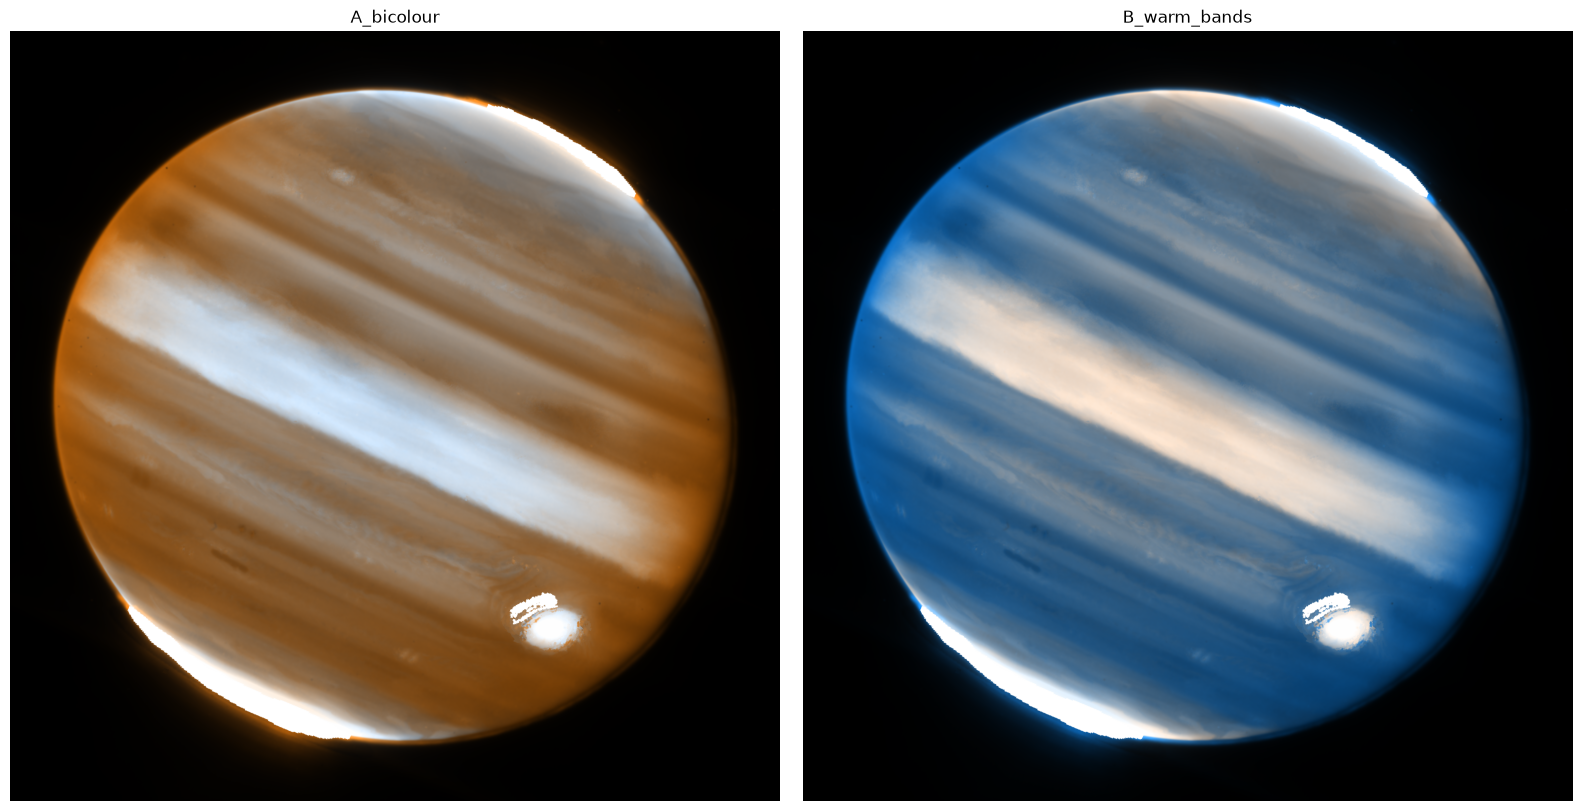

In [15]:
st3 = dict(stretched)
st3["SYN"] = 0.5 * (stretched["F212N"] + stretched["F335M"])

VARIANTS = {
    "A_bicolour": dict(hues={"F212N": 240, "SYN": 120, "F335M": 0},
                       label="chromatic order: F212N blue, synthetic mean channel green, F335M red"),
    "B_warm_bands": dict(hues={"F212N": 35, "F335M": 200},
                         label="chosen freely: F212N gold-orange, F335M cyan-blue"),
}


def make_rgb(v):
    rgb = color.compose(st3, color.mapping_from_degrees(v["hues"], v.get("sat", {})), v.get("weights", {}))
    if "lum" in v:
        rgb = color.apply_luminance(rgb, st3[v["lum"][0]], v["lum"][1])
    return rgb


rgbs = {k: make_rgb(v) for k, v in VARIANTS.items()}
fig, axes = plt.subplots(1, len(rgbs), figsize=(8 * len(rgbs), 8), squeeze=False)
for ax, (k, rgb) in zip(axes[0], rgbs.items()):
    ax.imshow(rgb, origin="lower")
    ax.set_title(k)
    ax.axis("off")
plt.tight_layout()

### 7b. Before/after: unflagged dark spots

The same colour image (`A_bicolour`) built once from the data as delivered and once after filling the dark spots from step 5b. Left: whole planet, boxes = the four deepest spots. Right: each spot before | after (≈ 2.5″ × 2.5″). The spots are only in F335M, so in the chromatic image they show up as small dark-blue dots (missing red).

deepest spots (y, x) and depth: [((456, 346), 0.41), ((891, 1409), 0.43), ((1289, 1291), 0.44), ((1292, 1286), 0.44)]


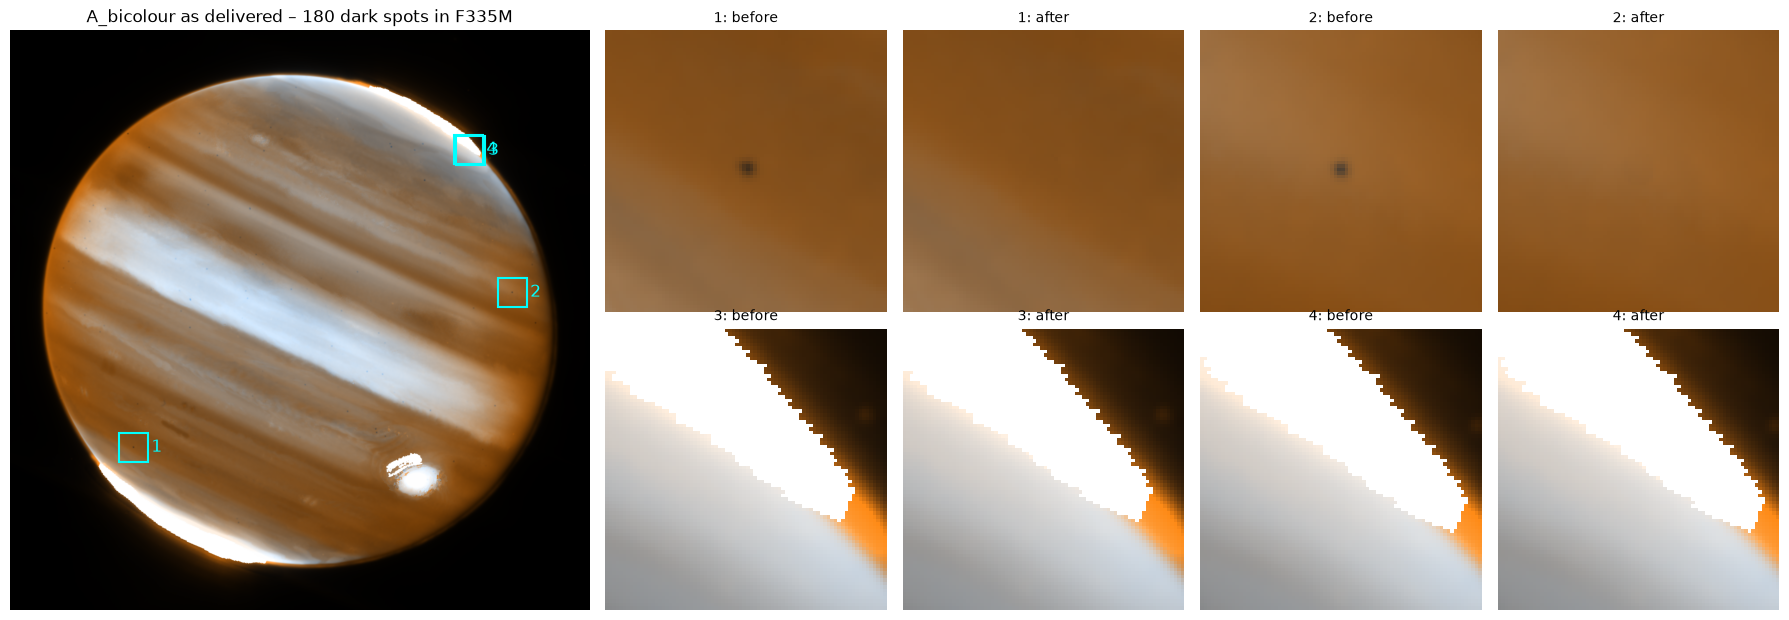

In [16]:
from matplotlib.patches import Rectangle

COMPARE_VARIANT, HALF = "A_bicolour", 40          # crop half-size in px (40 px ≈ 1.2″)


def rgb_from(filled_set, v):
    st, _ = stretch.stretch_all(filled_set, valid, stats, params)
    if UNIFY_SATURATED:
        for b in st:
            st[b][sat_union] = 1.0
    st["SYN"] = 0.5 * (st["F212N"] + st["F335M"])
    rgb = color.compose(st, color.mapping_from_degrees(v["hues"], v.get("sat", {})), v.get("weights", {}))
    if "lum" in v:
        rgb = color.apply_luminance(rgb, st[v["lum"][0]], v["lum"][1])
    return rgb


rgb_before = rgb_from(unfixed, VARIANTS[COMPARE_VARIANT])
rgb_after = rgbs[COMPARE_VARIANT]

# the four deepest spots
b0 = DARK_SPOT_BANDS[0]
lab, nlab = ndi.label(dark_spots[b0])
ratio = unfixed[b0] / ndi.median_filter(unfixed[b0], DARK_MED)
depth = ndi.minimum(ratio, lab, np.arange(1, nlab + 1))
order = np.argsort(depth)[:4]
cents = ndi.center_of_mass(dark_spots[b0], lab, np.arange(1, nlab + 1))
pick = [tuple(int(round(c)) for c in cents[i]) for i in order]
print("deepest spots (y, x) and depth:", [(p, round(float(depth[i]), 2)) for p, i in zip(pick, order)])

fig, ax = plt.subplot_mosaic([["full", "full", "b0", "a0", "b1", "a1"],
                              ["full", "full", "b2", "a2", "b3", "a3"]], figsize=(18, 6.2))
ax["full"].imshow(rgb_before, origin="lower")
ax["full"].set_title(f"{COMPARE_VARIANT} as delivered – {n_dark[b0]} dark spots in {b0}")
for k, (y, x) in enumerate(pick):
    ax["full"].add_patch(Rectangle((x - HALF, y - HALF), 2 * HALF, 2 * HALF, fill=False, ec="cyan", lw=1.5))
    ax["full"].text(x + HALF + 10, y, str(k + 1), color="cyan", fontsize=12, va="center")
    for tag, img in (("b", rgb_before), ("a", rgb_after)):
        a = ax[f"{tag}{k}"]
        a.imshow(img[y - HALF:y + HALF, x - HALF:x + HALF], origin="lower", interpolation="nearest")
        a.set_title(f"{k + 1}: {'before' if tag == 'b' else 'after'}", fontsize=10)
for a in ax.values():
    a.axis("off")
plt.tight_layout()
fig.savefig(ROOT / "output/jupiter_dark_spots_comparison.jpg", dpi=150, bbox_inches="tight")

## 8. Export

Chosen variants (`EXPORT`) as TIFF/PNG (full resolution) and web JPEG + caption; parameters to `params/jupiter.json`.

In [17]:
EXPORT = ["A_bicolour", "B_warm_bands"]
DATE = fits.getheader(next(iter(FILES.values())), 0)["DATE-BEG"][:10]
north_up, east_left = export.orientation(wcs_out, n // 2, n // 2)
print("north up:", north_up, "  east left:", east_left)


def caption_for(name):
    v = VARIANTS[name]
    table = "\n".join(f"| {b if b != 'SYN' else 'synthetic (mean of F212N and F335M)'} | {v['hues'][b]:.0f}° |"
                       for b in v["hues"])
    steps = ["calibrated stage-3 images (`_i2d.fits`) from MAST, one pair of filters exposed simultaneously "
             "(no rotation between them)",
             ("row destriping on empty sky (no high-pass)" if USE_DESTRIPE else "no destriping")
             + (" + 2-D background (128 px)" if USE_BG2D else ""),
             f"close-up grid {RES:.3f}″/px centred on Jupiter (`reproject_adaptive`; F335M upsampled ×2)",
             "background from empty corners",
             f"asinh stretch (a = {A_VALUE}" + (f", per filter {A_BAND}" if A_BAND else "") + f"), white point from "
             f"the measured disk pixels ({WHITE_PCT_DISK} %), each filter normalised to its own white point",
             "additive colour mixing" + (" with a synthetic channel (mean of both filters)" if "SYN" in VARIANTS[name]["hues"] else ""),
             "bad/flagged pixels filled with the local median; large saturated areas on the planet "
             "(bright limb haze, around the Great Red Spot in F335M) set to white; no local adjustments",
             f"isolated dark spots in F335M not flagged by the pipeline ({n_dark.get('F335M', 0)}, probably bad values "
             "in one of three dither exposures) filled with the local median",]
    return f"""# Jupiter – JWST NIRCam

Jupiter, observed on {DATE} with NIRCam on the James Webb Space Telescope (programme {PROGRAM}, observation {PAIR.split('_')[0].split('-')[1]}). Field of view ≈ {FIELD_ARCSEC:.0f}″ × {FIELD_ARCSEC:.0f}″, {"north up, east left" if (north_up and east_left) else "ORIENTATION TO BE CHECKED"}. Only two filters, exposed at the same time; a third colour channel is synthetic.

## Colour assignment ({name}: {v['label']})

| Filter | Hue |
|---|---|
{table}

The recorded light is infrared; all colours are an assignment, not "true" colours.

## Processing

{" → ".join(steps)}. Notebook `14_jupiter.ipynb`; all values in `params/jupiter.json`.

## Credits

Data: NASA, ESA, CSA, STScI (programme {PROGRAM}), retrieved via MAST. Processing: Tritium13.
"""


paths = {}
for name in EXPORT:
    paths[name] = export.save_outputs(rgbs[name], caption_for(name), f"{TARGET.lower()}_{name}",
                                      ROOT / "output/full_res", ROOT / "output")
    print(name, "->", [p.name for p in paths[name]])
json.dump({"files": {b: f.name for b, f in FILES.items()}, "pair": PAIR,
           "grid": {"centre_radec": [ra0, dec0], "pixel_arcsec": RES, "size_px": n},
           "disk_centre_yx": {b: list(c) for b, c in cen.items()}, "use_destripe": USE_DESTRIPE, "use_bg2d": USE_BG2D,
           "unify_saturated": UNIFY_SATURATED, "sky_boxes": [list(map(int, bx)) for bx in boxes],
           "stretch": {b: {**params[b], **stats[b], **levels[b]} for b in params},
           "colour_variants": VARIANTS, "exported": EXPORT},
          open(ROOT / f"params/{TARGET.lower()}.json", "w"), indent=2, default=float)

north up: True   east left: True
A_bicolour -> ['jupiter_A_bicolour_16bit.tif', 'jupiter_A_bicolour_full.png', 'jupiter_A_bicolour_web.jpg', 'jupiter_A_bicolour_caption.md']
B_warm_bands -> ['jupiter_B_warm_bands_16bit.tif', 'jupiter_B_warm_bands_full.png', 'jupiter_B_warm_bands_web.jpg', 'jupiter_B_warm_bands_caption.md']


## Conclusion

- **Only simultaneous filters.** Jupiter rotates by roughly 0.6° per minute, so filters taken at different times would shift the clouds against each other. One simultaneous SW/LW pair avoids that; the price is two filters and a synthetic third channel. "De-rotating" more pairs is left for later.
- **The planet needed its own mask.** The disk mask from Neptune/Uranus found only ~12″ of the ~40″ disk; `planet_mask` (5 % of the 99th percentile, largest region) covers the whole planet.
- **Saturation.** In F335M, about 28 900 px are saturated (bright limb haze, the arc around the Great Red Spot). Without treatment they turned black; now NaN on the planet (mask + 15 px) are set to white, and the white point is measured only on real pixels.
- **Flagged pixels.** The diagnostic cell shows NaN pixels clustering at sharp, moving features (rim of the GRS, small clouds). Probably the pipeline's outlier rejection reacting to Jupiter's rotation between dithers – not verified. After filling with the local median they are no longer visible.
- **Unflagged dark spots.** Besides the NaN pixels, F335M contains ~55 isolated dark spots on the disk (15–50 % below their surroundings, typically ~⅓), already present in the MAST i2d with full weight – i.e. not flagged by the pipeline. They only appear in F335M, not in the simultaneous F212N, so they are very likely not real features. The typical depth fits one bad value among three dither exposures (not verified – would need the stage-2 `_cal` files). Filled with the local median (threshold 0.85 of a 15 px median, ≤ 40 px; at 0.9 the same search already finds real structure in F212N). Before/after in step 7b and `output/jupiter_dark_spots_comparison.jpg`.
- **Stretch.** Jupiter is much brighter and higher in contrast than Neptune/Uranus (a = 0.01–0.02 there); a = 0.2 works best here.
- **Unflagged dark spots.** Besides the NaN pixels, F335M contains ~55 isolated dark spots on the disk (15–50 % below their surroundings, typically ~⅓), already present in the MAST i2d with full weight – i.e. not flagged by the pipeline. They only appear in F335M, not in the simultaneous F212N, so they are very likely not real features. The typical depth fits one bad value among three dither exposures (not verified – would need the stage-2 `_cal` files). Filled with the local median (threshold 0.85 of a 15 px median, ≤ 40 px; at 0.9 the same search already finds real structure in F212N).
- Next: generalise the planet template, then bring `run.py` up to the notebook state.